## Bologna Green Areas Exploration

Layers explored ~ built:
  1. DBSN  ar_vrd   → parks / gardens (types "01", "95")
  2. DBSN  bosco    → woodland / forest patches
  3. DBSN  pe_unis  → uniform open spaces (might include public squares / green)
  4. OSM            → leisure=park / garden

=> Accessibility-eligible criteria (300m rule):
  • publicly accessible  (not private / restricted)


In [3]:
!pip install fiona

  Using cached click_plugins-1.1.1.2-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached cligj-0.7.2-py3-none-any.whl.metadata (5.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 4.3 MB/s  0:00:03m0:00:0100:01
Using cached click_plugins-1.1.1.2-py2.py3-none-any.whl (11 kB)
Using cached cligj-0.7.2-py3-none-any.whl (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━ 2/3 [fiona]  WARNING: The script fio is installed in '/Library/Frameworks/Python.framework/Versions/3.12/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [fiona]


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import osmnx as ox
import fiona
import os
import numpy as np
import matplotlib.gridspec as gridspec


os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

In [41]:
CRS_WGS    = "EPSG:4326"
CRS_METRIC = "EPSG:32632"

DBSN_GDB = "/Users/terezasaskova/Downloads/BO_dbsn_2025-07-28/Bologna_dbsn.gdb"
OUT_GPKG  = "data/300m/bologna_greenery.gpkg"

PRIVATE_ACCESS = {"private", "no", "restricted", "permit", "customers"}

boundary = gpd.read_file("data/bologna_boundary.gpkg").to_crs(CRS_METRIC)
boundary_ha = boundary.geometry.area.sum() / 1e4

In [42]:
def area_ha(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    #add area_ha column 
    gdf = gdf.copy()
    gdf["area_ha"] = gdf.geometry.area / 1e4
    return gdf

def clip_and_reset(gdf, boundary):
    return gdf.pipe(gpd.clip, boundary).reset_index(drop=True)

def describe_areas(gdf):
    print(f"Features : {len(gdf):,}")
    if "area_ha" in gdf.columns:
        d = gdf["area_ha"].describe().round(0)
        print(f"Area (ha): median={d['50%']}, total={gdf['area_ha'].sum():.1f}")

## DBSN - AREA VERDE (ar_vrd)

- Columns : ['ar_vrd_ty', 'scril', 'meta_ist', 'classid', 'shape_Length', 'shape_Area', 'geometry']
- with the attribute ar_vrd_ty:
01 => not qualified garden
95 => other


In [47]:
ar_vrd = gpd.read_file(DBSN_GDB, layer="ar_vrd").to_crs(CRS_METRIC)
print(f"Total features: {len(ar_vrd):,}")
print(ar_vrd["ar_vrd_ty"].value_counts().to_string())

av_green_areas = (
    ar_vrd
    .query('ar_vrd_ty in ["01", "95"]')   # parks + sport/recreation green
    .pipe(clip_and_reset, boundary)
    .pipe(area_ha)
)
av_green_areas = av_green_areas[av_green_areas['area_ha'] > 5]
print("ar_vrd: parks+gardens (types 01,95), bigger then 1 ha:")
describe_areas(av_green_areas)


Total features: 26,279
ar_vrd_ty
01    26231
95       48
ar_vrd: parks+gardens (types 01,95), bigger then 1 ha:
Features : 96
Area (ha): median=7.0, total=910.5


## DBSN - settlement units (pe_unis)
-   Columns : ['pe_uins_nm', 'pe_uins_ty', 'pe_uins_pa', 'scril', 'meta_ist', 'classid', 'shape_Length', 'shape_Area', 'geometry']
- the attribute pe_uins_ty you can identify: 
- 0301 => schools areas
- 0302 => hospital areas
- 0303 => cemeteries areas
- 04 => military areas
- 06 => industry areas
- 1001 => playgrounds
- 11 => park/garden - public or private
- 1101 => garden
- 1102 =>
- 1103 => park

In [63]:
pe_raw = gpd.read_file(DBSN_GDB, layer="pe_uins").to_crs(CRS_METRIC)
print(f"Total features : {len(pe_raw):,}")

pe_clipped = pe_raw.pipe(clip_and_reset, boundary).pipe(area_ha)

GREEN_TYPES = ["11", "1001", "1101", "1102", "1103"]  #park/garden/playground 

green_areas = (
    pe_clipped
    .loc[lambda df: df["pe_uins_ty"].isin(GREEN_TYPES)]
    .pipe(area_ha)
)
print("pe_unis:")
describe_areas(green_areas)

Total features : 3,794
pe_unis:
Features : 542
Area (ha): median=0.0, total=935.4


## OSM - leisure = park / garden

In [44]:
boundary_geom = boundary.geometry.union_all()  # single shapely polygon
boundary_wgs84 = gpd.GeoSeries([boundary_geom], crs=CRS_METRIC).to_crs(CRS_WGS).iloc[0]

PRIVATE_ACCESS = {"private", "no", "restricted", "permit", "customers"}

osm_raw = ox.features_from_polygon(
    boundary_wgs84,
    tags={"leisure": ["park", "garden"]}
).to_crs(CRS_METRIC).pipe(clip_and_reset, boundary).pipe(area_ha)

osm_raw = osm_raw[
    osm_raw.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

print(f"OSM parks+gardens — all: {len(osm_raw)}")
describe_areas(osm_raw)

osm_public = osm_raw.loc[
    osm_raw["access"].isna() | ~osm_raw["access"].isin(PRIVATE_ACCESS)
].copy()

print(f"OSM parks+gardens — public: {len(osm_public)}")
describe_areas(osm_public)


OSM parks+gardens — all: 1051
Features : 1,051
Area (ha): median=0.0, total=1173.2
OSM parks+gardens — public: 1026
Features : 1,026
Area (ha): median=0.0, total=1167.4


## SUMMARY COMPARISON


In [45]:
summary = pd.DataFrame([
    {"layer": "DBSN ar_vrd",       "filter": "all parks/gardens",         "n": len(av_green_areas),     "total_ha": av_green_areas.area_ha.sum(),     "pct": av_green_areas.area_ha.sum()/boundary_ha*100},
    {"layer": "DBSN pe_unis",       "filter": "all",                       "n": len(green_areas),       "total_ha": green_areas.area_ha.sum(),       "pct": green_areas.area_ha.sum()/boundary_ha*100},
    {"layer": "OSM park/garden",    "filter": "all public",                "n": len(osm_public),       "total_ha": osm_public.area_ha.sum(),       "pct": osm_public.area_ha.sum()/boundary_ha*100},
]).round({"total_ha": 1, "pct": 1})
print(summary.to_string(index=False))


          layer            filter    n  total_ha  pct
    DBSN ar_vrd all parks/gardens  793    2359.9 16.8
   DBSN pe_unis               all  542     935.4  6.7
OSM park/garden        all public 1026    1167.4  8.3


## Vizualization of source comparison + why to use settlement units + osm only

In [ ]:

C_ARVRD  = "#c44dff"
C_OSM    = "#00e676"
C_AGREE  = "#00e676"
C_ONLY_A = "#c44dff"
C_ONLY_O = "#00bfa5"
C_SETT   = "#FFD54F"
FIG_BG   = "#1a1a2e"
PAN_BG   = "#12122a"
LAND_BG  = "#2e2e4a"   

fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=200)
fig.patch.set_facecolor(FIG_BG)
for ax in axes:
    ax.set_facecolor(PAN_BG)

def add_base(ax):
    """Dark municipality fill so it reads as a map."""
    boundary.plot(ax=ax, color=LAND_BG, zorder=0)
    boundary.boundary.plot(ax=ax, color="white", linewidth=1.0,
                           alpha=0.6, zorder=5)

def add_settlements(ax):
    green_areas.boundary.plot(
        ax=ax, color=C_SETT, linewidth=0.7,
        linestyle="--", alpha=0.85, zorder=4
    )

def add_legend(ax, handles):
    ax.legend(
        handles=handles, fontsize=8, loc="upper right",
        framealpha=0.55, facecolor="#0a0a1a",
        labelcolor="white", edgecolor="none",
        handlelength=1.4, handleheight=1.0,
    )

def style_ax(ax, title, subtitle):
    ax.set_title(title, fontsize=11, fontweight="bold",
                 color="white", pad=7)
    ax.text(0.5, -0.015, subtitle,
            transform=ax.transAxes, ha="center",
            fontsize=8.5, color="#aaaacc")
    ax.set_axis_off()

def callout(ax, text, fc):
    ax.annotate(
        text, xy=(0.5, 0.04), xycoords="axes fraction",
        ha="center", fontsize=8, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.45", fc=fc, alpha=0.88, ec="none"),
    )

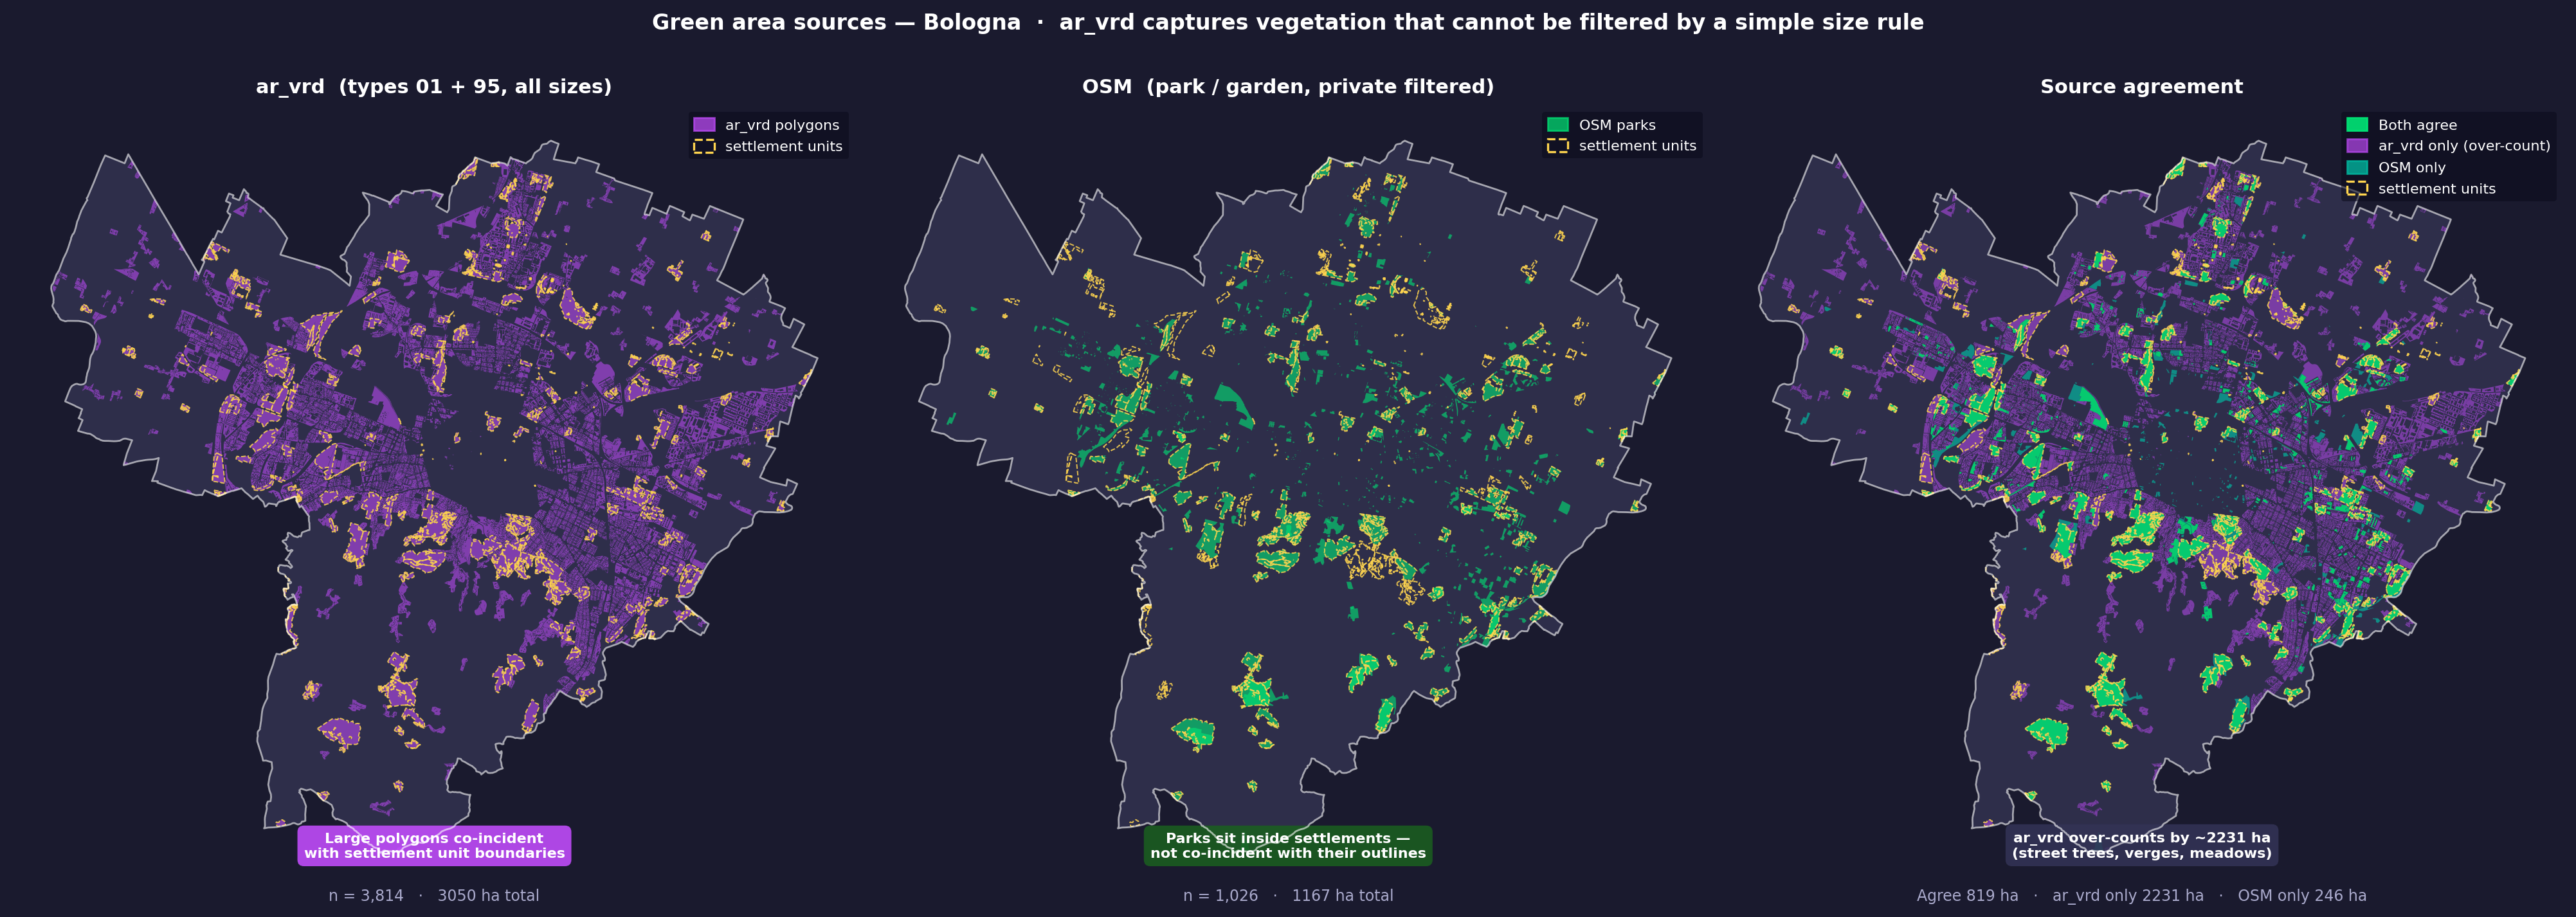

Saved.


In [ ]:
ar_vrd_clipped = ar_vrd.pipe(clip_and_reset, boundary).pipe(area_ha)
arvrd_union    = ar_vrd_clipped.dissolve().geometry.iloc[0]
osm_union      = osm_public.dissolve().geometry.iloc[0]

agree      = gpd.GeoDataFrame(geometry=[arvrd_union.intersection(osm_union)], crs=ar_vrd_clipped.crs)
only_arvrd = gpd.GeoDataFrame(geometry=[arvrd_union.difference(osm_union)],   crs=ar_vrd_clipped.crs)
only_osm   = gpd.GeoDataFrame(geometry=[osm_union.difference(arvrd_union)],   crs=ar_vrd_clipped.crs)

n1  = len(ar_vrd_clipped);  ha1 = ar_vrd_clipped.geometry.area.sum() / 1e4
n2  = len(osm_public);      ha2 = osm_public.geometry.area.sum()      / 1e4
ha_agree = agree.geometry.area.sum()      / 1e4
ha_a     = only_arvrd.geometry.area.sum() / 1e4
ha_o     = only_osm.geometry.area.sum()   / 1e4

ax = axes[0]
add_base(ax)
ar_vrd_clipped.plot(ax=ax, color=C_ARVRD, alpha=0.55, zorder=2)
add_settlements(ax)

callout(ax, "Large polygons co-incident\nwith settlement unit boundaries", C_ARVRD)
add_legend(ax, [
    mpatches.Patch(color=C_ARVRD, alpha=0.7, label="ar_vrd polygons"),
    mpatches.Patch(facecolor="none", edgecolor=C_SETT,
                   linestyle="--", linewidth=1.2, label="settlement units"),
])
style_ax(ax,
    title="ar_vrd  (types 01 + 95, all sizes)",
    subtitle=f"n = {n1:,}   ·   {ha1:.0f} ha total")

ax = axes[1]
add_base(ax)
osm_public.plot(ax=ax, color=C_OSM, alpha=0.60, zorder=2)   
add_settlements(ax)

callout(ax, "Parks sit inside settlements —\nnot co-incident with their outlines", "#1b5e20")
add_legend(ax, [
    mpatches.Patch(color=C_OSM, alpha=0.7, label="OSM parks"),
    mpatches.Patch(facecolor="none", edgecolor=C_SETT,
                   linestyle="--", linewidth=1.2, label="settlement units"),
])
style_ax(ax,
    title="OSM  (park / garden, private filtered)",
    subtitle=f"n = {n2:,}   ·   {ha2:.0f} ha total")

ax = axes[2]
add_base(ax)
only_arvrd.plot(ax=ax, color=C_ONLY_A, alpha=0.50, zorder=2)
only_osm.plot(  ax=ax, color=C_ONLY_O, alpha=0.65, zorder=2)
agree.plot(     ax=ax, color=C_AGREE,  alpha=0.85, zorder=3)
add_settlements(ax)

callout(ax, f"ar_vrd over-counts by ~{ha_a:.0f} ha\n(street trees, verges, meadows)", "#333355")
add_legend(ax, [
    mpatches.Patch(color=C_AGREE,  alpha=0.9,  label="Both agree"),
    mpatches.Patch(color=C_ONLY_A, alpha=0.65, label="ar_vrd only (over-count)"),
    mpatches.Patch(color=C_ONLY_O, alpha=0.75, label="OSM only"),
    mpatches.Patch(facecolor="none", edgecolor=C_SETT,
                   linestyle="--", linewidth=1.2, label="settlement units"),
])
style_ax(ax,
    title="Source agreement",
    subtitle=f"Agree {ha_agree:.0f} ha -   ar_vrd only {ha_a:.0f} ha   -   OSM only {ha_o:.0f} ha")

fig.suptitle(
    "Green area sources — Bologna"
    "ar_vrd captures vegetation that cannot be filtered by a simple size rule",
    fontsize=12, fontweight="bold", color="white", y=1.02,
)
plt.tight_layout(pad=0.6)
plt.savefig("fig/fig5_green_areas_sources.png", dpi=200,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## Source choice
- based on the vizual comparison
- based on the very noticable overcount by area verde
- based on co-incident of bigger polygons of area verde and pe units
- based on good coverage of osm 

- we choose open street map(filter out parks and gardens with private tag) + pe units(settlment units - filter for greenery codes)

In [62]:

# Standardise columns before saving
def prep_save(gdf, source, layer_type):
    cols = ["geometry", "area_ha"]
    # keep name if present
    for c in ["nome", "name", "descrizione", "NOME", "NAME"]:
        if c in gdf.columns:
            cols.append(c)
            break
    return gdf[cols].assign(source=source, layer_type=layer_type).copy()

layers_to_save = {
    #"ar_vrd":   prep_save(av_green_areas,      "DBSN", "av_green_areas"),
    "pe_unis_all":       prep_save(green_areas,     "DBSN", "pe_unis_all"),
    "osm_public":    prep_save(osm_public,     "OSM",  "osm_public"),
}

for layer_name, gdf in layers_to_save.items():
    gdf.to_file(OUT_GPKG, layer=layer_name, driver="GPKG")
    print(f" {layer_name:25s}  ({len(gdf):,} features)")



 pe_unis_all                (542 features)
 osm_public                 (1,026 features)
